# SHAP 分析：YBI RTS 易发性模型

本 notebook 用 SHAP 解释当前分支上的 YBI RTS 易发性模型。它直接调用项目已有的特征准备 artifact、StandardScaler、5 折 PyTorch MLP 权重，并把 SHAP 作用在原始 16 个环境因子上。

## tl;dr

- 目标：解释模型输出的 susceptibility probability，识别全局重要因子、方向性以及单个坡单元的局部贡献。
- 默认模型：dbscan 路由、ndcg_aware_lambdarank、bs_128 的已选择 5 折 ensemble。
- 解释函数：原始 16 个因子 → 每折独立预处理与标准化 → 5 折平均预测。
- 输出：全局 mean(|SHAP|) 表、SHAP bar/beeswarm 图、top 因子 dependence 图和一个高预测样本的局部贡献图。
- SHAP 前置诊断：全部基于通过质量校验的原始 16 个因子；Vegetation_type 保留原始类别编码，并补充 eta association。
- 当前默认执行结果：5893 行中 5889 行可用于分析；SHAP 结果显示 NDVI 的 mean(|SHAP|) 为 0.1330，最大加和误差为 0。

运行最后的 Takeaways 单元格后，摘要中的数值会随顶部参数和当前 artifact 自动更新；上面的数值对应默认 bs_128 配置。

## Context & Methods

模型训练时将 16 个原始环境因子展开为模型实际使用的输入列：Vegetation_type 做 one-hot，Soil 和 GIC 增加缺失指示列，随后按每一折保存的 StandardScaler 标准化。Notebook 不重新拟合这些步骤，而是读取训练时保存的 artifact，避免解释函数与推理函数不一致。

SHAP 使用 PermutationExplainer，因为需要解释的是包含 pandas 预处理和 5 折 ensemble 的黑盒预测函数。解释目标是 5 折平均的预测概率，而不是 raw logit 或 ranking loss。每个 SHAP 值的单位是模型输出概率；正值表示该因子在该样本上把预测推向更高的易发性，负值表示推向更低的易发性。

### Key Assumptions

- 默认使用训练特征表 Dataset_Construction/outputs/03_environmental_data/Total_features_sample.csv 的确定性样本；这用于解释模型学习到的规律，不等同于对全部 1.86M 个空间坡单元逐一计算 SHAP。
- Vegetation_type 以原始整数类别输入；Permutation masker 交换观测到的类别，不对类别做连续插值。
- SHAP background 和 explanation 样本量在顶部参数中可调整。增大样本量通常提高稳定性，但会线性增加 CPU 计算时间。
- SHAP 是模型归因，不是因果效应；特征相关性可能使贡献在相关因子之间分摊。
- 如果 notebook 不在仓库目录下运行，可设置环境变量 YBIRTS_REPO_ROOT 指向仓库根目录；运行环境需要包含 torch、shap、pyyaml、pandas、scikit-learn 和 matplotlib。

### 1. Configure the analysis

In [1]:
import json
import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display

RANDOM_SEED = 42

# The branch currently contains the selected dbscan ensemble at bs_128.
# Change this to 256, 512, or 1024 to explain another saved ensemble.
MODEL_BATCH_SIZE = 128
ROUTE = "dbscan"
RANK_LOSS_MODE = "ndcg_aware_lambdarank"

# Permutation SHAP is intentionally sampled so the notebook remains practical on CPU.
BACKGROUND_SIZE = 64
EXPLAIN_SIZE = 64
SHAP_MAX_EVALS = None  # None -> the minimum 2 * n_features + 1 evaluations per row.

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
)


def find_repo_root(start_path):
    for candidate in (start_path, *start_path.parents):
        if (candidate / "YBI_Ranking_Framework" / "src" / "cvrank" / "model.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Repository root not found. Run this notebook from the repository or set "
        "YBIRTS_REPO_ROOT to the repository root."
    )


configured_root = os.environ.get("YBIRTS_REPO_ROOT")
REPO_ROOT = Path(configured_root).expanduser().resolve() if configured_root else find_repo_root(Path.cwd())
DATA_PATH = REPO_ROOT / "Dataset_Construction" / "outputs" / "03_environmental_data" / "Total_features_sample.csv"
MODEL_ROOT = (
    REPO_ROOT
    / "YBI_Ranking_Framework"
    / "data"
    / "output"
    / f"output_{ROUTE}_selected"
    / f"bs_{MODEL_BATCH_SIZE}"
    / RANK_LOSS_MODE
)
SELECTED_CONFIG_PATH = MODEL_ROOT / "selection" / f"{ROUTE}_best_train.yaml"
FOLD_MANIFEST_PATH = MODEL_ROOT / "fold_runs_manifest.json"

for required_path in (DATA_PATH, SELECTED_CONFIG_PATH, FOLD_MANIFEST_PATH):
    if not required_path.is_file():
        raise FileNotFoundError(f"Required artifact not found: {required_path}")

print(f"Repository: {REPO_ROOT}")
print(f"Data: {DATA_PATH}")
print(f"Selected config: {SELECTED_CONFIG_PATH}")
print(f"Background / explanation rows: {BACKGROUND_SIZE} / {EXPLAIN_SIZE}")

Repository: D:\orca\workspaces\YBIRTS_Susceptibility\SUYBIRTS_Susceptibility
Data: D:\orca\workspaces\YBIRTS_Susceptibility\SUYBIRTS_Susceptibility\Dataset_Construction\outputs\03_environmental_data\Total_features_sample.csv
Selected config: D:\orca\workspaces\YBIRTS_Susceptibility\SUYBIRTS_Susceptibility\YBI_Ranking_Framework\data\output\output_dbscan_selected\bs_128\ndcg_aware_lambdarank\selection\dbscan_best_train.yaml
Background / explanation rows: 64 / 64


### 2. Load the selected ensemble and its fold-specific preprocessing

In [2]:
SRC_ROOT = REPO_ROOT / "YBI_Ranking_Framework" / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

try:
    import torch
except ImportError as exc:
    raise ImportError(
        "PyTorch is required. Select the same environment used to train the YBI model."
    ) from exc

from cvrank.data_utils import apply_feature_preparation_artifact, load_feature_preparation_artifact
from cvrank.shared import build_model

torch.set_num_threads(1)


def resolve_repo_path(value):
    candidate = Path(str(value))
    if candidate.exists():
        return candidate

    normalized = str(value).replace("\\", "/")
    lower_normalized = normalized.lower()
    for marker in (
        "YBI_Ranking_Framework",
        "Dataset_Construction",
        "Susceptibility_Mapping",
    ):
        marker_index = lower_normalized.rfind(marker.lower())
        if marker_index >= 0:
            rebuilt = REPO_ROOT / normalized[marker_index:].replace("/", os.sep)
            if rebuilt.exists():
                return rebuilt

    raise FileNotFoundError(f"Artifact path from manifest does not exist: {value}")


selected_config = yaml.safe_load(SELECTED_CONFIG_PATH.read_text(encoding="utf-8"))
selected_config["data_path"] = str(DATA_PATH)
fold_manifest = json.loads(FOLD_MANIFEST_PATH.read_text(encoding="utf-8"))
fold_metadata = sorted(fold_manifest.get("folds", []), key=lambda item: int(item["fold_index"]))

if not fold_metadata:
    raise ValueError(f"No fold entries found in {FOLD_MANIFEST_PATH}")

raw_feature_cols = list(selected_config["feature_cols"])
label_col = str(selected_config.get("label_col", "Label_Cls"))
year_col = str(selected_config.get("year_col", "Feature_Year"))
input_nodata_values = None
fold_bundles = []


def load_state_dict(model_path):
    try:
        state = torch.load(model_path, map_location="cpu", weights_only=True)
    except TypeError:
        state = torch.load(model_path, map_location="cpu")
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    return state


for fold_meta in fold_metadata:
    fold_index = int(fold_meta["fold_index"])
    model_path = resolve_repo_path(fold_meta["model_path"])
    scaler_path = resolve_repo_path(fold_meta["scaler_path"])
    preparation_path = resolve_repo_path(fold_meta["feature_preparation_path"])

    artifact = load_feature_preparation_artifact(preparation_path)
    final_feature_cols = list(artifact["final_feature_cols"])
    with scaler_path.open("rb") as handle:
        scaler = pickle.load(handle)

    model = build_model(input_dim=len(final_feature_cols), config=selected_config)
    model.load_state_dict(load_state_dict(model_path))
    model.eval()

    if input_nodata_values is None:
        input_nodata_values = tuple(
            float(value) for value in artifact.get("input_nodata_values", [-9999.0])
        )

    fold_bundles.append(
        {
            "fold_index": fold_index,
            "model": model,
            "scaler": scaler,
            "artifact": artifact,
            "model_path": model_path,
            "scaler_path": scaler_path,
            "preparation_path": preparation_path,
            "final_feature_cols": final_feature_cols,
        }
    )

if input_nodata_values is None:
    input_nodata_values = (-9999.0,)

reference_final_feature_cols = fold_bundles[0]["final_feature_cols"]
for bundle in fold_bundles:
    if list(bundle["artifact"]["raw_feature_cols"]) != raw_feature_cols:
        raise ValueError("Fold artifacts disagree with the selected raw feature columns.")
    if bundle["final_feature_cols"] != reference_final_feature_cols:
        raise ValueError("Fold artifacts disagree on the final model feature columns.")

bundle_summary = pd.DataFrame(
    [
        {
            "fold": bundle["fold_index"],
            "final_input_features": len(bundle["final_feature_cols"]),
            "model_file": bundle["model_path"].name,
            "scaler_file": bundle["scaler_path"].name,
        }
        for bundle in fold_bundles
    ]
)
display(bundle_summary)
print(
    f"Loaded {len(fold_bundles)} folds; "
    f"{len(raw_feature_cols)} raw features -> {len(reference_final_feature_cols)} model features."
)

,fold,final_input_features,model_file,scaler_file
0,0,25,dbscan_fold_0_bs_128_model.pth,dbscan_fold_0_bs_128_scaler.pkl
1,1,25,dbscan_fold_1_bs_128_model.pth,dbscan_fold_1_bs_128_scaler.pkl
2,2,25,dbscan_fold_2_bs_128_model.pth,dbscan_fold_2_bs_128_scaler.pkl
3,3,25,dbscan_fold_3_bs_128_model.pth,dbscan_fold_3_bs_128_scaler.pkl
4,4,25,dbscan_fold_4_bs_128_model.pth,dbscan_fold_4_bs_128_scaler.pkl


Loaded 5 folds; 16 raw features -> 25 model features.


## Data

### 3. Load and validate the raw analysis table

In [3]:
raw_table = pd.read_csv(DATA_PATH)

required_columns = [label_col, year_col, *raw_feature_cols]
missing_columns = [column for column in required_columns if column not in raw_table.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

raw_feature_table = raw_table.loc[:, raw_feature_cols].copy()
(
    _prepared_reference,
    _reference_final_cols,
    invalid_numeric_mask,
    missing_required_raw_na_mask,
    missing_required_input_nodata_mask,
) = apply_feature_preparation_artifact(
    raw_feature_table,
    raw_feature_cols,
    input_nodata_values,
    fold_bundles[0]["artifact"],
    fill_numeric_imputation=True,
)

invalid_feature_mask = (
    invalid_numeric_mask
    | missing_required_raw_na_mask
    | missing_required_input_nodata_mask
)
usable_mask = ~invalid_feature_mask
analysis_table = raw_table.loc[usable_mask].reset_index(drop=True).copy()

data_quality_summary = pd.DataFrame(
    [
        {
            "raw_rows": int(len(raw_table)),
            "usable_rows": int(len(analysis_table)),
            "dropped_rows": int((~usable_mask).sum()),
            "dropped_pct": float((~usable_mask).mean() * 100.0),
            "raw_features": len(raw_feature_cols),
            "model_features_after_preparation": len(reference_final_feature_cols),
        }
    ]
)
display(data_quality_summary.round({"dropped_pct": 4}))

print("Label distribution in the usable rows:")
display(
    analysis_table[label_col]
    .value_counts(dropna=False)
    .rename("rows")
    .rename_axis(label_col)
    .reset_index()
)

print("Year distribution in the usable rows:")
display(
    analysis_table[year_col]
    .value_counts(dropna=False)
    .sort_index()
    .rename("rows")
    .rename_axis(year_col)
    .reset_index()
)

,raw_rows,usable_rows,dropped_rows,dropped_pct,raw_features,model_features_after_preparation
0,5893,5889,4,0.0679,16,25


Label distribution in the usable rows:


,Label_Cls,rows
0,1,2004
1,0,2000
2,-1,1885


Year distribution in the usable rows:


,Feature_Year,rows
0,2016,3008
1,2017,1525
2,2018,566
3,2019,690
4,2020,100


### 4. Define the full ensemble prediction function

In [4]:
def as_raw_feature_frame(values):
    if isinstance(values, pd.DataFrame):
        frame = values.loc[:, raw_feature_cols].copy()
    else:
        array = np.asarray(values)
        if array.ndim == 1:
            array = array.reshape(1, -1)
        if array.ndim != 2 or array.shape[1] != len(raw_feature_cols):
            raise ValueError(
                f"Expected a 2D array with {len(raw_feature_cols)} raw features; "
                f"got shape {array.shape}."
            )
        frame = pd.DataFrame(array, columns=raw_feature_cols)

    for column in raw_feature_cols:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame


def predict_ensemble_probability(values):
    raw_features = as_raw_feature_frame(values)
    fold_probabilities = []

    for bundle in fold_bundles:
        transformed, final_cols, invalid_mask, missing_na_mask, missing_nodata_mask = (
            apply_feature_preparation_artifact(
                raw_features,
                raw_feature_cols,
                input_nodata_values,
                bundle["artifact"],
                fill_numeric_imputation=True,
            )
        )
        problem_mask = (
            invalid_mask
            | missing_na_mask
            | missing_nodata_mask
            | transformed.isna().any(axis=1)
        )
        if bool(problem_mask.any()):
            bad_rows = problem_mask[problem_mask].index.tolist()[:5]
            raise ValueError(
                f"Prediction input contains invalid rows at positions {bad_rows}. "
                "Use the validated analysis table or provide complete raw features."
            )

        model_input = bundle["scaler"].transform(
            transformed.loc[:, list(final_cols)].to_numpy(dtype=np.float32, copy=True)
        )
        with torch.inference_mode():
            _, probability = bundle["model"](
                torch.as_tensor(model_input, dtype=torch.float32)
            )
        fold_probabilities.append(probability.cpu().numpy().reshape(-1))

    return np.column_stack(fold_probabilities).mean(axis=1)


analysis_table["predicted_susceptibility"] = predict_ensemble_probability(
    analysis_table.loc[:, raw_feature_cols]
)
prediction_min = float(analysis_table["predicted_susceptibility"].min())
prediction_max = float(analysis_table["predicted_susceptibility"].max())
if not (0.0 <= prediction_min <= prediction_max <= 1.0):
    raise AssertionError(
        f"Ensemble probabilities are outside [0, 1]: {prediction_min}, {prediction_max}"
    )

display(
    analysis_table["predicted_susceptibility"]
    .describe()
    .to_frame("predicted_susceptibility")
    .round(6)
)
print(
    f"Prediction sanity check passed: min={prediction_min:.6f}, max={prediction_max:.6f}"
)

,predicted_susceptibility
count,5889.000000
mean,0.599672
std,0.382156
min,0.000171
25%,0.185220
50%,0.716910
75%,0.982517
max,0.998672


Prediction sanity check passed: min=0.000171, max=0.998672


## Results

### 5. Sample deterministic background and explanation rows

In [5]:
def stratified_sample(frame, n, stratify_col, seed):
    n = min(int(n), len(frame))
    if n <= 0:
        raise ValueError("The requested sample size must be positive.")
    if n >= len(frame):
        return frame.sample(frac=1.0, random_state=seed).reset_index(drop=True)

    grouped = list(frame.groupby(stratify_col, dropna=False, sort=True))
    if n < len(grouped):
        return frame.sample(n=n, random_state=seed).reset_index(drop=True)

    group_lookup = {key: group for key, group in grouped}
    quotas = {
        key: max(1, int(np.floor(n * len(group) / len(frame))))
        for key, group in grouped
    }

    while sum(quotas.values()) > n:
        reducible = [key for key, quota in quotas.items() if quota > 1]
        key = max(reducible, key=lambda item: quotas[item])
        quotas[key] -= 1

    while sum(quotas.values()) < n:
        key = max(
            quotas,
            key=lambda item: len(group_lookup[item]) - quotas[item],
        )
        quotas[key] += 1

    sampled_parts = [
        group_lookup[key].sample(
            n=quotas[key],
            random_state=seed + offset,
        )
        for offset, (key, _group) in enumerate(grouped)
    ]
    return (
        pd.concat(sampled_parts, axis=0)
        .sample(frac=1.0, random_state=seed)
        .reset_index(drop=True)
    )


background_table = stratified_sample(
    analysis_table,
    BACKGROUND_SIZE,
    label_col,
    RANDOM_SEED,
)
explanation_table = stratified_sample(
    analysis_table,
    EXPLAIN_SIZE,
    label_col,
    RANDOM_SEED + 1,
)
background_inputs = background_table.loc[:, raw_feature_cols].copy()
explanation_inputs = explanation_table.loc[:, raw_feature_cols].copy()

display(
    pd.DataFrame(
        {
            "sample": ["background", "explanation"],
            "rows": [len(background_table), len(explanation_table)],
            "label_counts": [
                background_table[label_col].value_counts().sort_index().to_dict(),
                explanation_table[label_col].value_counts().sort_index().to_dict(),
            ],
        }
    )
)

,sample,rows,label_counts
0,background,64,"{-1: 20, 0: 21, 1: 23}"
1,explanation,64,"{-1: 20, 0: 21, 1: 23}"


## Feature diagnostics

相关性和共线性诊断必须在 SHAP 之前完成。所有计算均使用通过质量校验的原始 16 个因子，不使用预处理、标准化或模型展开后的变量。Vegetation_type 保留原始类别编码，并与其他原始因子一起计算 Pearson/Spearman 和 VIF；由于它是名义类别，这部分结果依赖类别编码顺序，仅作为筛查，同时报告更适合类别变量的 eta association。

### 6. Correlation matrix and high-correlation pairs

In [6]:
raw_diagnostic_features = analysis_table.loc[:, raw_feature_cols].apply(
    pd.to_numeric, errors="coerce"
)
if raw_diagnostic_features.isna().any().any():
    raise ValueError("Raw diagnostic feature table contains missing values after validation.")

categorical_feature_cols = [
    column for column in ("Vegetation_type",) if column in raw_feature_cols
]
continuous_feature_cols = [
    column for column in raw_feature_cols if column not in categorical_feature_cols
]
continuous_features = raw_diagnostic_features.loc[:, continuous_feature_cols]

# Correlation screening uses the original raw factor columns, including the raw category code.
pearson_corr = raw_diagnostic_features.corr(method="pearson")
spearman_corr = raw_diagnostic_features.corr(method="spearman")
CORRELATION_THRESHOLD = 0.8


def correlation_pairs(correlation_matrix):
    rows = []
    columns = list(correlation_matrix.columns)
    for left_index, left in enumerate(columns):
        for right in columns[left_index + 1 :]:
            value = float(correlation_matrix.loc[left, right])
            rows.append(
                {
                    "feature_1": left,
                    "feature_2": right,
                    "correlation": value,
                    "abs_correlation": abs(value),
                }
            )
    return pd.DataFrame(rows).sort_values(
        "abs_correlation", ascending=False, ignore_index=True
    )


pearson_pairs = correlation_pairs(pearson_corr)
spearman_pairs = correlation_pairs(spearman_corr)
strong_pearson_pairs = pearson_pairs[
    pearson_pairs["abs_correlation"] >= CORRELATION_THRESHOLD
].copy()
strong_spearman_pairs = spearman_pairs[
    spearman_pairs["abs_correlation"] >= CORRELATION_THRESHOLD
].copy()

vegetation_categories = (
    raw_diagnostic_features["Vegetation_type"].astype("string").fillna("missing")
)
vegetation_eta_rows = []
for feature_name in continuous_feature_cols:
    valid_mask = continuous_features[feature_name].notna() & vegetation_categories.notna()
    values = continuous_features.loc[valid_mask, feature_name].to_numpy(dtype=float)
    categories = vegetation_categories.loc[valid_mask].to_numpy()
    grand_mean = float(values.mean())
    grouped_values = pd.DataFrame(
        {"category": categories, "value": values}
    ).groupby("category")["value"]
    between_sum_squares = sum(
        len(group) * (float(group.mean()) - grand_mean) ** 2
        for _, group in grouped_values
    )
    total_sum_squares = float(((values - grand_mean) ** 2).sum())
    eta = (
        float(np.sqrt(between_sum_squares / total_sum_squares))
        if total_sum_squares > 0
        else np.nan
    )
    vegetation_eta_rows.append(
        {"feature": feature_name, "eta_with_Vegetation_type": eta}
    )

vegetation_eta = pd.DataFrame(vegetation_eta_rows).sort_values(
    "eta_with_Vegetation_type", ascending=False, ignore_index=True
)

print(f"Raw factors assessed: {len(raw_feature_cols)}")
print(f"Continuous factors: {len(continuous_feature_cols)}; categorical factors: {categorical_feature_cols}")
print("Pearson/Spearman matrices use the original raw factor columns; Vegetation_type uses its raw category code.")
print(f"Pearson pairs with |r| >= {CORRELATION_THRESHOLD}: {len(strong_pearson_pairs)}")
display(strong_pearson_pairs.head(20).round(4))
print(f"Spearman pairs with |rho| >= {CORRELATION_THRESHOLD}: {len(strong_spearman_pairs)}")
display(strong_spearman_pairs.head(20).round(4))
print("Vegetation_type association with continuous factors (eta):")
display(vegetation_eta.round(4))

Raw factors assessed: 16
Continuous factors: 15; categorical factors: ['Vegetation_type']
Pearson/Spearman matrices use the original raw factor columns; Vegetation_type uses its raw category code.
Pearson pairs with |r| >= 0.8: 4


,feature_1,feature_2,correlation,abs_correlation
0,TDD,WSTmax,0.8292,0.8292
1,Slope,Local_Relief,0.8124,0.8124
2,Slope,Slope_std,0.8076,0.8076
3,Precipitation,Summer_SoilMoisture,0.8057,0.8057


Spearman pairs with |rho| >= 0.8: 2


,feature_1,feature_2,correlation,abs_correlation
0,Slope,Slope_std,0.8636,0.8636
1,Precipitation,Summer_SoilMoisture,0.8341,0.8341


Vegetation_type association with continuous factors (eta):


,feature,eta_with_Vegetation_type
0,NDVI,0.5797
1,Slope,0.4970
2,Precipitation,0.4725
3,Summer_SoilMoisture,0.4179
4,Local_Relief,0.3846
5,Slope_std,0.3824
6,TWI,0.3572
7,Soil,0.3010
8,WSTmax,0.2356
9,SMDP,0.2245


### 7. Pearson and Spearman heatmaps

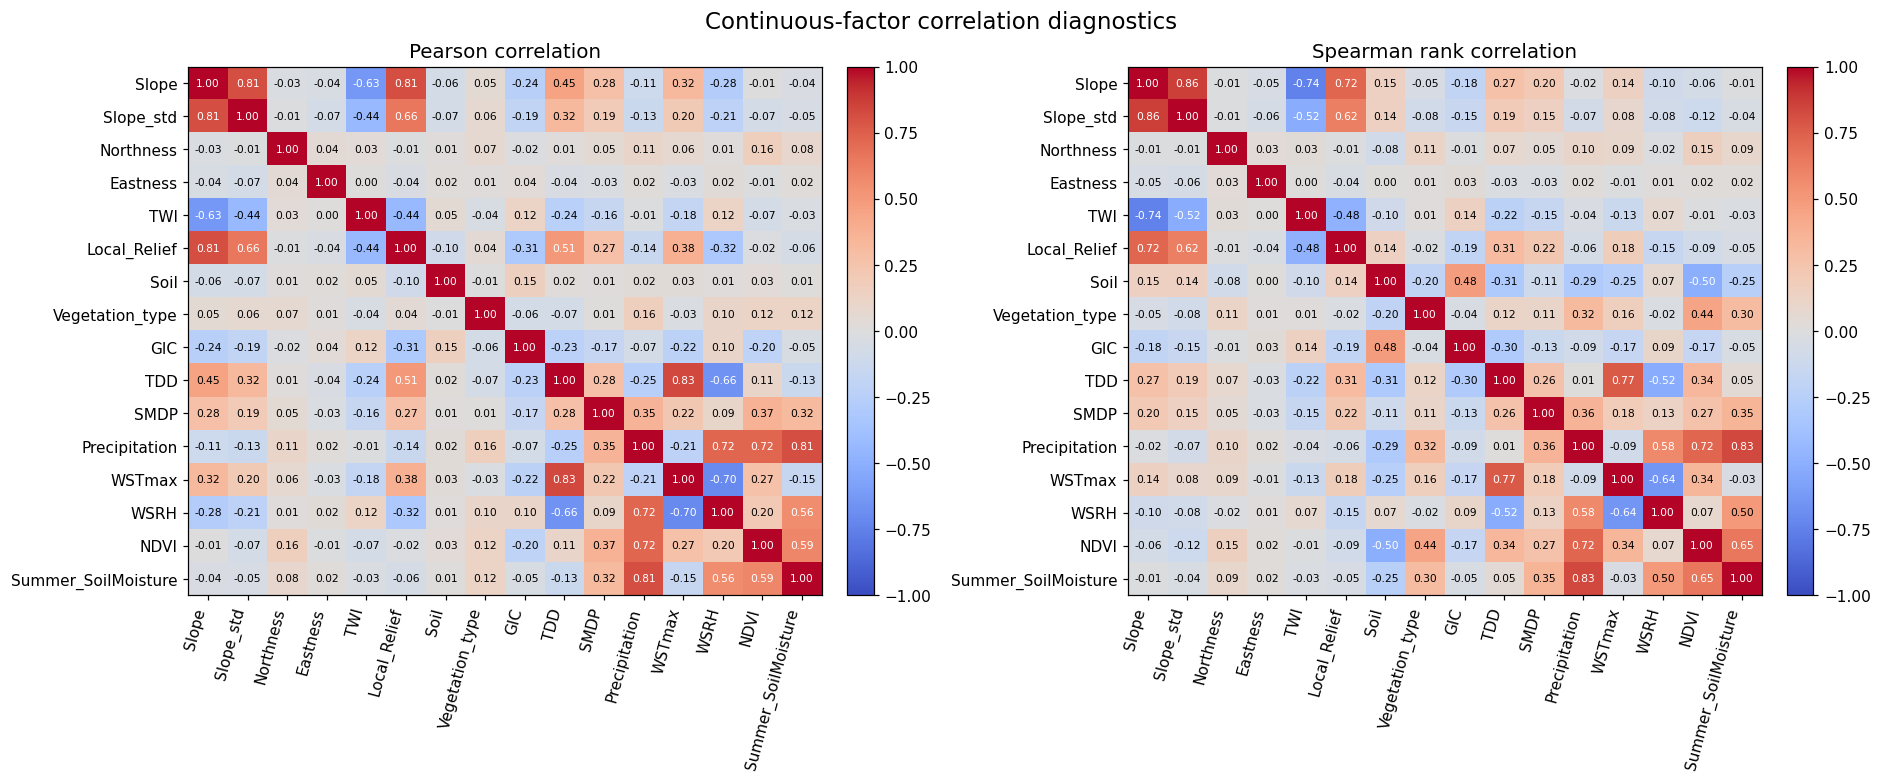

In [7]:
fig, axes = plt.subplots(
    1, 2, figsize=(17, 7), constrained_layout=True
)
for axis, matrix, title in zip(
    axes,
    (pearson_corr, spearman_corr),
    ("Pearson correlation", "Spearman rank correlation"),
):
    values = matrix.to_numpy(dtype=float)
    image = axis.imshow(
        values,
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
        aspect="auto",
    )
    axis.set_xticks(range(len(matrix.columns)))
    axis.set_yticks(range(len(matrix.index)))
    axis.set_xticklabels(matrix.columns, rotation=75, ha="right")
    axis.set_yticklabels(matrix.index)
    axis.set_title(title)
    for row_index in range(values.shape[0]):
        for column_index in range(values.shape[1]):
            coefficient = float(values[row_index, column_index])
            text_color = "white" if abs(coefficient) >= 0.5 else "black"
            axis.text(
                column_index,
                row_index,
                f"{coefficient:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color=text_color,
            )
    axis.grid(False)
    fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)

fig.suptitle("Continuous-factor correlation diagnostics", fontsize=15)
plt.show()

### 8. VIF and condition number

In [8]:
# VIF is evaluated on the original raw factor columns, not one-hot or scaled model columns.
vif_design = raw_diagnostic_features.loc[:, raw_feature_cols].copy().astype(float)

constant_features = [
    column for column in vif_design.columns if float(vif_design[column].std(ddof=0)) <= 1e-12
]
vif_design = vif_design.drop(columns=constant_features)
if vif_design.shape[1] == 0:
    raise ValueError("No non-constant features remain for VIF diagnostics.")

# For a full-rank design, VIF is the diagonal of the inverse feature-correlation matrix.
# This is algebraically equivalent to fitting one regression per feature.
standardized_design = (
    vif_design - vif_design.mean(axis=0)
) / vif_design.std(axis=0, ddof=0)
standardized_matrix = standardized_design.to_numpy(dtype=float)
if not np.isfinite(standardized_matrix).all():
    raise ValueError("VIF design contains non-finite values after standardization.")

design_correlation = np.corrcoef(standardized_matrix, rowvar=False)
design_rank = int(np.linalg.matrix_rank(design_correlation))
if design_rank < design_correlation.shape[0]:
    # Exact rank deficiency makes the traditional VIF undefined/infinite.
    vif_values = np.full(design_correlation.shape[0], np.inf)
    vif_method = "rank-deficient raw-factor design; VIF reported as infinite"
else:
    vif_values = np.diag(np.linalg.inv(design_correlation))
    vif_method = "inverse raw-factor correlation matrix"

vif_table = pd.DataFrame(
    {"feature": vif_design.columns, "vif": vif_values}
).sort_values("vif", ascending=False, ignore_index=True)
vif_table["flag"] = np.select(
    [
        np.isinf(vif_table["vif"]),
        vif_table["vif"] >= 10.0,
        vif_table["vif"] >= 5.0,
    ],
    ["infinite", "severe", "warning"],
    default="ok",
)

condition_number = float(
    np.linalg.cond(standardized_matrix)
)

diagnostic_summary = pd.DataFrame(
    [
        {
            "continuous_features": len(continuous_feature_cols),
            "raw_vif_features": int(vif_design.shape[1]),
            "categorical_features": ", ".join(categorical_feature_cols) or "none",
            "design_rank": design_rank,
            "vif_method": vif_method,
            "constant_features_dropped": ", ".join(constant_features) or "none",
            "max_abs_pearson": float(pearson_pairs["abs_correlation"].max()),
            "max_abs_spearman": float(spearman_pairs["abs_correlation"].max()),
            "max_vif": float(vif_table["vif"].max()),
            "condition_number": condition_number,
        }
    ]
)
display(diagnostic_summary.round(4))
display(vif_table.round(4))
print("VIF uses the original raw factor columns; no one-hot or scaled model columns are used.")
print(
    "VIF interpretation: values >= 5 are flagged as a warning and values >= 10 "
    "as severe; use the table together with the correlation matrices and domain context."
)

,continuous_features,raw_vif_features,categorical_features,design_rank,vif_method,constant_features_dropped,max_abs_pearson,max_abs_spearman,max_vif,condition_number
0,15,16,Vegetation_type,16,inverse raw-factor correlation matrix,none,0.8292,0.8636,10.2176,8.378


,feature,vif,flag
0,Precipitation,10.2176,severe
1,WSRH,7.2641,warning
2,Slope,6.6987,warning
3,WSTmax,5.3575,warning
4,NDVI,4.3756,ok
5,TDD,4.3644,ok
6,Local_Relief,3.4093,ok
7,Slope_std,3.0264,ok
8,Summer_SoilMoisture,2.9696,ok
9,TWI,1.7883,ok


VIF uses the original raw factor columns; no one-hot or scaled model columns are used.
VIF interpretation: values >= 5 are flagged as a warning and values >= 10 as severe; use the table together with the correlation matrices and domain context.


### 9. Compute permutation SHAP values

In [9]:
# SHAP 0.49 imports a 3x3 color-conversion matrix through scipy.linalg.inv.
# On some Windows conda builds the LAPACK-backed call aborts during import; NumPy's
# implementation is numerically equivalent for this fixed 3x3 initialization.
if sys.platform == "win32":
    import scipy.linalg as scipy_linalg

    scipy_linalg.inv = np.linalg.inv

try:
    import shap
except ImportError as exc:
    raise ImportError(
        "SHAP is required for this notebook. Install it in the active model environment "
        "with python -m pip install shap."
    ) from exc

minimum_max_evals = 2 * len(raw_feature_cols) + 1
effective_max_evals = (
    minimum_max_evals if SHAP_MAX_EVALS is None else int(SHAP_MAX_EVALS)
)
if effective_max_evals < minimum_max_evals:
    raise ValueError(
        f"SHAP_MAX_EVALS must be at least {minimum_max_evals} for "
        f"{len(raw_feature_cols)} features."
    )

masker = shap.maskers.Independent(background_inputs)
explainer = shap.Explainer(
    predict_ensemble_probability,
    masker,
    algorithm="permutation",
    feature_names=raw_feature_cols,
    seed=RANDOM_SEED,
)
np.random.seed(RANDOM_SEED)
shap_values = explainer(
    explanation_inputs,
    max_evals=effective_max_evals,
    silent=True,
)
shap_array = np.asarray(shap_values.values, dtype=float)
explanation_predictions = predict_ensemble_probability(explanation_inputs)
base_values = np.asarray(shap_values.base_values, dtype=float).reshape(-1)
shap_reconstructed = base_values + shap_array.sum(axis=1)
additivity_errors = shap_reconstructed - explanation_predictions
max_additivity_error = float(np.max(np.abs(additivity_errors)))

if shap_array.shape != (len(explanation_inputs), len(raw_feature_cols)):
    raise AssertionError(
        f"Unexpected SHAP shape: {shap_array.shape}; "
        f"expected {(len(explanation_inputs), len(raw_feature_cols))}."
    )
if max_additivity_error >= 1e-4:
    raise AssertionError(
        f"SHAP additivity check failed; maximum absolute error is {max_additivity_error:.6g}."
    )

reconciliation = pd.DataFrame(
    {
        "prediction": explanation_predictions,
        "shap_base_value": base_values,
        "shap_sum_plus_base": shap_reconstructed,
        "additivity_error": additivity_errors,
    }
)
display(reconciliation.head(8).round(8))
print(
    f"SHAP {shap.__version__} complete: shape={shap_array.shape}, "
    f"max |additivity error|={max_additivity_error:.3e}"
)

C:\Users\LPF\anaconda3\envs\ML\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,prediction,shap_base_value,shap_sum_plus_base,additivity_error
0,0.997331,0.574201,0.997331,0.0
1,0.996884,0.574201,0.996884,0.0
2,0.839298,0.574201,0.839298,0.0
3,0.928715,0.574201,0.928715,0.0
4,0.013035,0.574201,0.013035,0.0
5,0.026085,0.574201,0.026085,0.0
6,0.237293,0.574201,0.237293,0.0
7,0.977934,0.574201,0.977934,0.0


SHAP 0.49.1 complete: shape=(64, 16), max |additivity error|=0.000e+00


### 10. Global importance and group comparison

In [10]:
global_importance = pd.DataFrame(
    {
        "feature": raw_feature_cols,
        "mean_abs_shap": np.abs(shap_array).mean(axis=0),
        "mean_shap": shap_array.mean(axis=0),
        "positive_share": (shap_array > 0).mean(axis=0),
    }
).sort_values("mean_abs_shap", ascending=False, ignore_index=True)
global_importance["importance_pct"] = (
    global_importance["mean_abs_shap"]
    / global_importance["mean_abs_shap"].sum()
    * 100.0
)

display(
    global_importance[
        ["feature", "mean_abs_shap", "mean_shap", "positive_share", "importance_pct"]
    ].round(6)
)

group_importance_rows = []
for label_value, group in explanation_table.groupby(label_col, sort=True):
    row_indices = group.index.to_numpy(dtype=int)
    group_values = shap_array[row_indices]
    group_importance = pd.DataFrame(
        {
            "feature": raw_feature_cols,
            "mean_abs_shap": np.abs(group_values).mean(axis=0),
            "mean_shap": group_values.mean(axis=0),
        }
    ).sort_values("mean_abs_shap", ascending=False)
    for rank, record in enumerate(group_importance.head(5).itertuples(index=False), start=1):
        group_importance_rows.append(
            {
                "label": label_value,
                "rank": rank,
                "feature": record.feature,
                "mean_abs_shap": record.mean_abs_shap,
                "mean_shap": record.mean_shap,
                "group_rows": len(row_indices),
            }
        )

display(pd.DataFrame(group_importance_rows).round(6))

,feature,mean_abs_shap,mean_shap,positive_share,importance_pct
0,NDVI,0.132993,0.004725,0.437500,19.198204
1,Vegetation_type,0.083820,0.017183,0.750000,12.099740
2,TDD,0.052485,-0.011024,0.500000,7.576386
3,WSRH,0.048917,0.006397,0.625000,7.061425
4,Slope,0.048832,-0.017043,0.734375,7.049194
5,Summer_SoilMoisture,0.042556,0.001395,0.562500,6.143192
6,Slope_std,0.039274,0.000641,0.468750,5.669347
7,Northness,0.036807,0.003702,0.640625,5.313299
8,Precipitation,0.034937,-0.011021,0.359375,5.043292
9,GIC,0.033506,-0.003277,0.359375,4.836777


,label,rank,feature,mean_abs_shap,mean_shap,group_rows
0,-1,1,NDVI,0.130695,0.065011,20
1,-1,2,TDD,0.064436,-0.005835,20
2,-1,3,Vegetation_type,0.063439,0.054961,20
3,-1,4,Slope,0.049262,-0.009888,20
4,-1,5,WSRH,0.046453,0.016189,20
5,0,1,NDVI,0.133451,-0.084613,21
6,0,2,Vegetation_type,0.111568,-0.083329,21
7,0,3,Slope,0.067527,-0.056083,21
8,0,4,Summer_SoilMoisture,0.053214,-0.043907,21
9,0,5,WSRH,0.049390,-0.022912,21


### 11. Global SHAP bar plot

C:\Users\LPF\AppData\Local\Temp\ipykernel_30408\3384186530.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


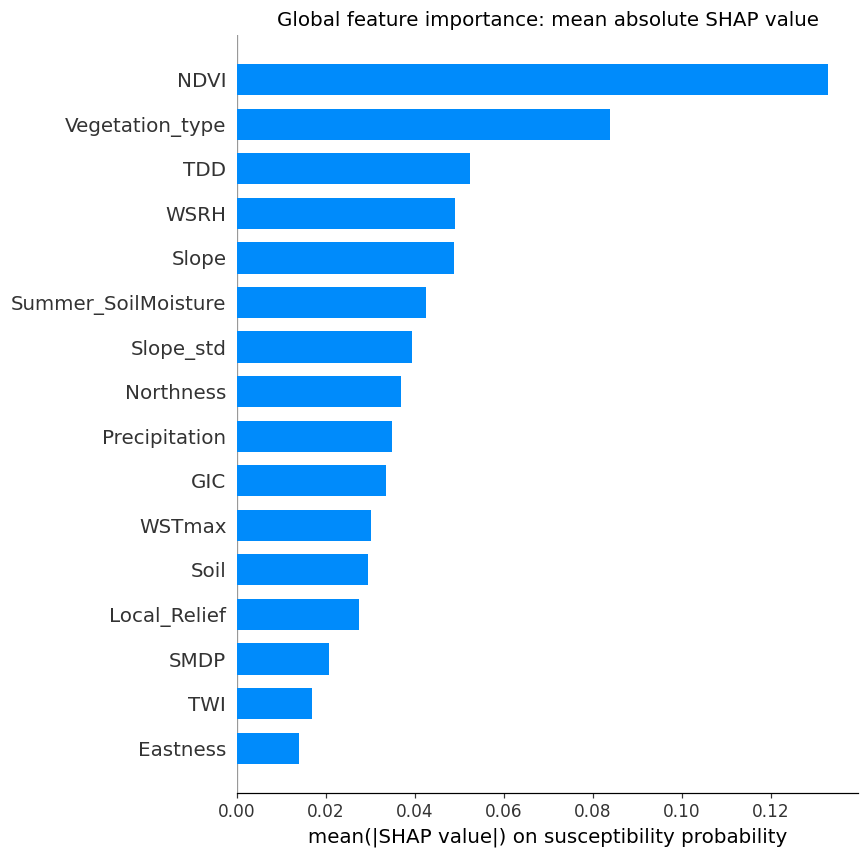

In [11]:
plt.figure(figsize=(9, 6))
shap.summary_plot(
    shap_array,
    explanation_inputs,
    feature_names=raw_feature_cols,
    plot_type="bar",
    max_display=len(raw_feature_cols),
    show=False,
)
plt.title("Global feature importance: mean absolute SHAP value")
plt.xlabel("mean(|SHAP value|) on susceptibility probability")
plt.tight_layout()
plt.show()

### 12. SHAP beeswarm plot

C:\Users\LPF\AppData\Local\Temp\ipykernel_30408\3491903964.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


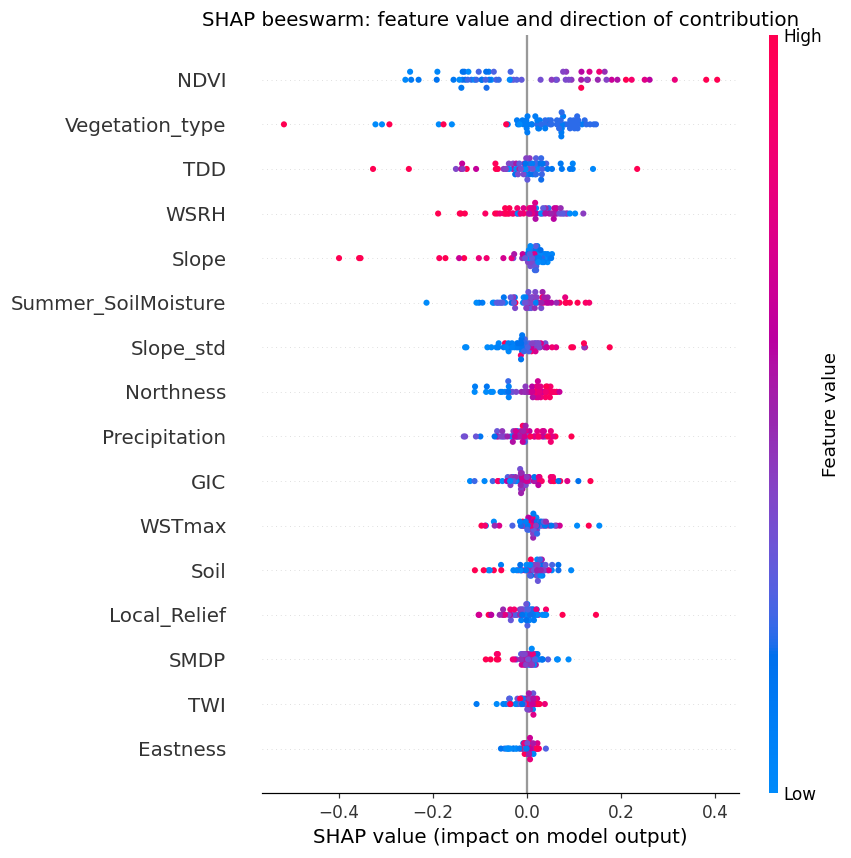

In [12]:
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_array,
    explanation_inputs,
    feature_names=raw_feature_cols,
    max_display=len(raw_feature_cols),
    show=False,
)
plt.title("SHAP beeswarm: feature value and direction of contribution")
plt.tight_layout()
plt.show()

### 13. Dependence plot for the most important feature

<Figure size 880x550 with 0 Axes>

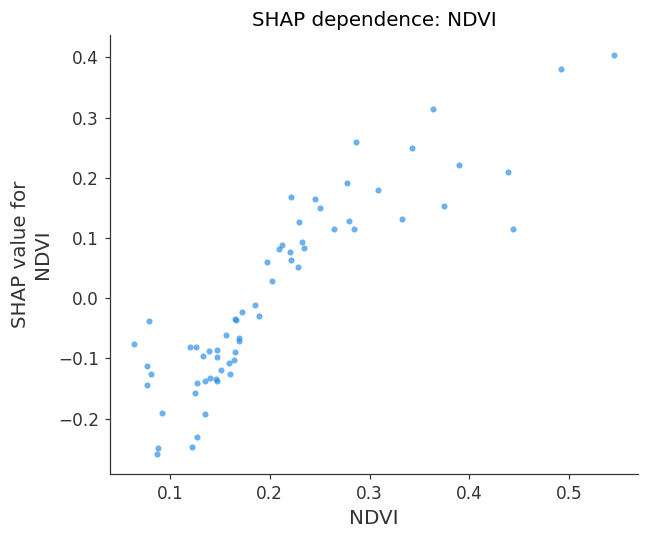

Displayed dependence plot for: NDVI


In [13]:
top_feature = str(global_importance.iloc[0]["feature"])
plt.figure(figsize=(8, 5))
shap.dependence_plot(
    top_feature,
    shap_array,
    explanation_inputs,
    feature_names=raw_feature_cols,
    interaction_index=None,
    alpha=0.65,
    show=False,
)
plt.title(f"SHAP dependence: {top_feature}")
plt.tight_layout()
plt.show()
print(f"Displayed dependence plot for: {top_feature}")

### 14. Local explanation for the highest predicted sample

,value
Sample_ID,HYBAS6_4060625570_000552
Feature_Year,2016
Label_Cls,1
predicted_susceptibility,0.997331


,feature,shap_value,abs_shap
0,NDVI,0.150029,0.150029
1,Vegetation_type,0.108432,0.108432
2,WSRH,0.085610,0.085610
3,Slope_std,-0.032479,0.032479
4,Soil,0.032445,0.032445
5,Slope,0.032010,0.032010
6,Summer_SoilMoisture,0.029744,0.029744
7,SMDP,0.016400,0.016400
8,Local_Relief,0.014114,0.014114
9,GIC,-0.013291,0.013291


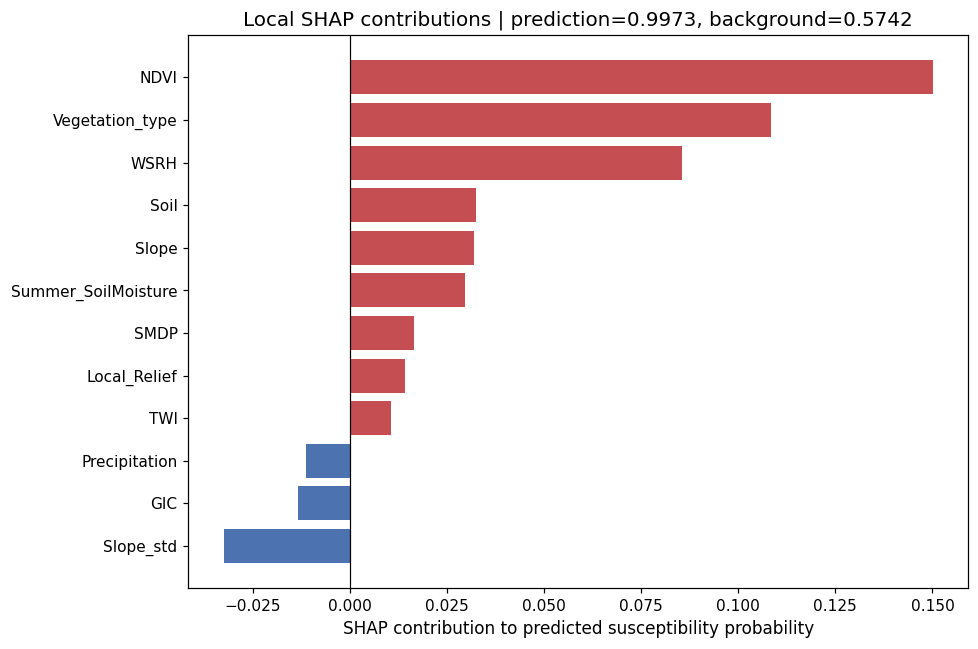

In [14]:
local_row_position = int(np.argmax(explanation_predictions))
local_row = explanation_table.iloc[local_row_position]
local_prediction = float(explanation_predictions[local_row_position])
local_base_value = float(base_values[local_row_position])

local_contributions = pd.DataFrame(
    {
        "feature": raw_feature_cols,
        "shap_value": shap_array[local_row_position],
    }
)
local_contributions["abs_shap"] = local_contributions["shap_value"].abs()
local_contributions = local_contributions.sort_values(
    "abs_shap", ascending=False, ignore_index=True
)
display(
    local_row[
        [column for column in ["Sample_ID", year_col, label_col] if column in local_row.index]
        + ["predicted_susceptibility"]
    ]
    .to_frame("value")
)
display(local_contributions.head(12).round(6))

plot_contributions = local_contributions.head(12).sort_values("shap_value")
colors = np.where(plot_contributions["shap_value"] >= 0, "#c44e52", "#4c72b0")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_contributions["feature"], plot_contributions["shap_value"], color=colors)
ax.axvline(0.0, color="black", linewidth=0.8)
ax.set_xlabel("SHAP contribution to predicted susceptibility probability")
ax.set_title(
    f"Local SHAP contributions | prediction={local_prediction:.4f}, "
    f"background={local_base_value:.4f}"
)
fig.tight_layout()
plt.show()

## Takeaways

### 15. Data-backed summary

In [15]:
top_global = global_importance.iloc[0]
most_positive = global_importance.sort_values("mean_shap", ascending=False).iloc[0]
most_negative = global_importance.sort_values("mean_shap", ascending=True).iloc[0]
mean_prediction = float(explanation_predictions.mean())
mean_base_value = float(base_values.mean())

summary = f"""
- 在当前 {len(explanation_inputs)} 个 explanation rows 上，mean(|SHAP|) 最大的因子是
  **{top_global["feature"]}**，平均绝对贡献为 **{top_global["mean_abs_shap"]:.4f}** 个概率点。
- 当前 explanation sample 的平均预测概率为 **{mean_prediction:.4f}**，
  SHAP background baseline 的平均值为 **{mean_base_value:.4f}**。
- 平均 SHAP 方向最偏向提高输出的是 **{most_positive["feature"]}**
  ({most_positive["mean_shap"]:+.4f})；最偏向降低输出的是 **{most_negative["feature"]}**
  ({most_negative["mean_shap"]:+.4f})。
- Additivity sanity check 的最大绝对误差为 **{max_additivity_error:.3e}**。
"""

display(Markdown(summary))
print(
    "Interpretation note: these are model attributions on the configured sample, "
    "not causal effects or independent physical sensitivities."
)


- 在当前 64 个 explanation rows 上，mean(|SHAP|) 最大的因子是
  **NDVI**，平均绝对贡献为 **0.1330** 个概率点。
- 当前 explanation sample 的平均预测概率为 **0.5725**，
  SHAP background baseline 的平均值为 **0.5742**。
- 平均 SHAP 方向最偏向提高输出的是 **Vegetation_type**
  (+0.0172)；最偏向降低输出的是 **Slope**
  (-0.0170)。
- Additivity sanity check 的最大绝对误差为 **0.000e+00**。


Interpretation note: these are model attributions on the configured sample, not causal effects or independent physical sensitivities.
